# Moirai 2.0: Zero-Shot Forecasting on ETTh1

**Paper**: *Moirai 2.0: When Less Is More for Time Series Forecasting*, Liu, Aksu, Liu, Liu, Yan, Pham, Savarese, Sahoo, Xiong, Li (Salesforce AI Research), arXiv preprint, 2025. [arXiv:2511.11698](https://arxiv.org/abs/2511.11698)

**Official code**: [SalesforceAIResearch/uni2ts](https://github.com/SalesforceAIResearch/uni2ts) (package `uni2ts==2.0.0`). **Weights**: [Salesforce/moirai-2.0-R-small](https://huggingface.co/Salesforce/moirai-2.0-R-small) (11.4M parameters).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/moirai2_zero_shot.ipynb)

**Key ideas**:
- **Decoder-only Transformer**: Moirai 1.0 was a masked encoder with mixture-distribution heads. Moirai 2.0 switches to a causal, decoder-only design: each patch token predicts the patches that follow it.
- **Quantile loss instead of a likelihood**: the head outputs 9 quantiles (q = 0.1, ..., 0.9) per future step, trained with the pinball loss.
- **Multi-token prediction**: one forward pass predicts the next 4 patches (4 x 16 = 64 steps). Longer horizons are rolled out autoregressively, and each quantile path is fed back in.
- **Single patch size (16)** with instance normalisation (`PackedStdScaler`) inside the model. The model is pretrained on a large multi-domain corpus (GIFT-Eval-compatible, no test leakage).
- **Smaller is better**: the small model (11M) is competitive with much larger foundation models on GIFT-Eval.

**What this notebook does**: zero-shot forecasting (no training at all) on the shared ETTh1 96-step benchmark, with lookback **L = 512** (main setting) and **L = 96**. The forecast uses the median (q = 0.5) and we report MSE/MAE on standardised data. Each of the 7 channels is forecast as an **independent univariate series**. All stride-1 test windows are scored, and inference runs batched on the GPU.

## Install

`uni2ts==2.0.0` pins `torch<2.5`, `numpy~=1.26`, `scipy~=1.11` and `gluonts~=0.14`. A plain `pip install uni2ts` on Colab therefore **downgrades torch (to 2.4.x) and numpy (to 1.26)**, and you would then have to restart the runtime. The forecasting code we use (`Moirai2Module` / `Moirai2Forecast`) runs fine on modern torch and numpy 2. So we install `uni2ts` and `gluonts` with `--no-deps` and add only the few pure-Python dependencies they import (`jaxtyping`, `lightning`, `einops`). This keeps Colab's default torch and numpy, and **no restart is needed**.

In [1]:
%pip install -q --no-deps uni2ts==2.0.0 gluonts==0.14.4
%pip install -q jaxtyping lightning einops

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time, json, random, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")

SEED = 2024
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}", f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
print("torch", torch.__version__, "| numpy", np.__version__)

Using device: cuda (NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition)
torch 2.12.1+cu130 | numpy 2.3.5


## Data: ETTh1 (shared benchmark setup)

We use the standard Informer/Autoformer/TSLib borders: 12 months train, 4 months val, 4 months test. A `StandardScaler` is fitted on the train rows only, and metrics are computed on the scaled data, as in the papers. The test split is prefixed with the last `L` points of validation, so the first test window forecasts the first test step. Stride 1 gives 2785 windows x 7 channels.

In [3]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

H = 96
_, _, test512, cols = load_etth1(512)
print("channels:", cols)
print("test split (L=512):", test512.shape, "-> windows:", len(WindowDataset(test512, 512, H)))

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
test split (L=512): (3392, 7) -> windows: 2785


## The model: `Moirai2Module` + `Moirai2Forecast`

`Moirai2Module` is the pretrained network. It works as follows:
1. **Patching**: the context of length $L$ is left-padded to a multiple of $P=16$ and cut into $\lceil L/P \rceil$ patch tokens.
2. **Instance scaling**: $\tilde{x} = (x-\mu)/\sigma$, with statistics taken from the observed context only.
3. **Causal Transformer** (6 layers, $d=384$ for *small*) over the patch tokens, with rotary time positions and variate ids.
4. **Quantile head**: the last context token emits $4$ future patches $\times$ $9$ quantiles $\times$ $16$ steps. Training minimises the pinball loss
$$\mathcal{L} = \sum_{q\in\{0.1,\dots,0.9\}} \sum_t \max\big(q\,(y_t-\hat y_t^{(q)}),\;(q-1)\,(y_t-\hat y_t^{(q)})\big).$$

For $H=96$ we need $96/16 = 6$ patches, which is more than the 4 the head emits per pass. `Moirai2Forecast.forward` therefore runs a second, autoregressive pass. It feeds each of the 9 quantile trajectories back as context and re-derives the 9 output quantiles from the resulting $9\times 9$ samples with `torch.quantile`.

`Moirai2Forecast.forward` already takes **batched torch tensors** `(batch, L, target_dim)`, so we call it directly on the GPU. This is the same code path the official `.predict()` uses, without GluonTS' per-series Python data pipeline, so stride-1 evaluation of ~19.5k series takes seconds.

In [4]:
from uni2ts.model.moirai2 import Moirai2Forecast, Moirai2Module
from importlib.metadata import version
print("uni2ts", version("uni2ts"))

module = Moirai2Module.from_pretrained("Salesforce/moirai-2.0-R-small")
n_params = sum(p.numel() for p in module.parameters())
print(f"params: {n_params/1e6:.2f}M | patch_size={module.patch_size} | "
      f"num_predict_token={module.num_predict_token} | quantiles={module.quantile_levels}")
QL = list(module.quantile_levels)
MED = QL.index(0.5)

def make_forecaster(L, H=96):
    # target_dim=1: each channel is an independent univariate series
    return Moirai2Forecast(module=module, prediction_length=H, context_length=L, target_dim=1,
                           feat_dynamic_real_dim=0, past_feat_dynamic_real_dim=0).to(device).eval()

uni2ts 2.0.0


params: 11.39M | patch_size=16 | num_predict_token=4 | quantiles=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


## Zero-shot evaluation (batched, stride 1, channel-independent)

Every `(window, channel)` pair becomes one univariate series of length `L`. We stack all of them and run the forecaster in GPU batches. The output has shape `(batch, 9 quantiles, H)`. The point forecast is the **median** (q = 0.5). As a quick check on calibration, we also report the empirical coverage of the 10-90% band, which should be about 80%.

In [5]:
@torch.no_grad()
def evaluate(L, batch_size=1024):
    _, _, test, _ = load_etth1(L)
    ds = WindowDataset(test, L, H, stride=1)
    X = np.stack([ds[k][0].numpy() for k in range(len(ds))])   # (N, L, C)
    Y = np.stack([ds[k][1].numpy() for k in range(len(ds))])   # (N, H, C)
    N, _, C = X.shape
    Xs = torch.from_numpy(X).permute(0, 2, 1).reshape(N * C, L, 1)  # channel-independent series
    f = make_forecaster(L, H)
    out = []
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for s in range(0, len(Xs), batch_size):
        x = Xs[s:s + batch_size].to(device)
        q = f(past_target=x,
              past_observed_target=torch.ones_like(x, dtype=torch.bool),
              past_is_pad=torch.zeros(x.shape[:2], dtype=torch.bool, device=device))
        out.append(q.float().cpu())
    if device.type == "cuda": torch.cuda.synchronize()
    secs = time.time() - t0
    Q = torch.cat(out).reshape(N, C, len(QL), H).permute(0, 2, 3, 1).numpy()  # (N, 9, H, C)
    pred = Q[:, MED]
    mse = float(((pred - Y) ** 2).mean()); mae = float(np.abs(pred - Y).mean())
    cov = float(((Y >= Q[:, 0]) & (Y <= Q[:, -1])).mean())
    print(f"L={L:4d}: {N} windows x {C} ch = {N*C} series | MSE {mse:.4f}  MAE {mae:.4f} | "
          f"10-90% coverage {cov:.3f} | {secs:.1f}s")
    per_ch = {c: (float(((pred[..., i] - Y[..., i])**2).mean()), float(np.abs(pred[..., i] - Y[..., i]).mean()))
              for i, c in enumerate(cols)}
    return dict(mse=mse, mae=mae, coverage_10_90=cov, seconds=secs, n_windows=N,
                per_channel=per_ch, X=X, Y=Y, Q=Q)

res = {L: evaluate(L) for L in (512, 96)}

L= 512: 2785 windows x 7 ch = 19495 series | MSE 0.3838  MAE 0.3803 | 10-90% coverage 0.749 | 19.1s


L=  96: 2785 windows x 7 ch = 19495 series | MSE 0.4346  MAE 0.4028 | 10-90% coverage 0.776 | 5.6s


In [6]:
print(pd.DataFrame({f"L={L}": {c: f"{m:.3f} / {a:.3f}" for c, (m, a) in r["per_channel"].items()}
                    for L, r in res.items()}).rename_axis("channel (MSE / MAE)"))

                             L=512           L=96
channel (MSE / MAE)                              
HUFL                 0.804 / 0.564  0.918 / 0.591
HULL                 0.206 / 0.335  0.222 / 0.352
MUFL                 0.827 / 0.556  0.952 / 0.584
MULL                 0.166 / 0.292  0.183 / 0.311
LUFL                 0.507 / 0.469  0.575 / 0.516
LULL                 0.119 / 0.264  0.133 / 0.279
OT                   0.056 / 0.182  0.058 / 0.185


## Forecast plot: OT channel with quantile bands

The input history, the ground truth and the Moirai 2.0 median forecast, with shaded 10-90% and 30-70% quantile bands. The panels show two test windows with lookback L = 512 (only the last 192 history steps are drawn).

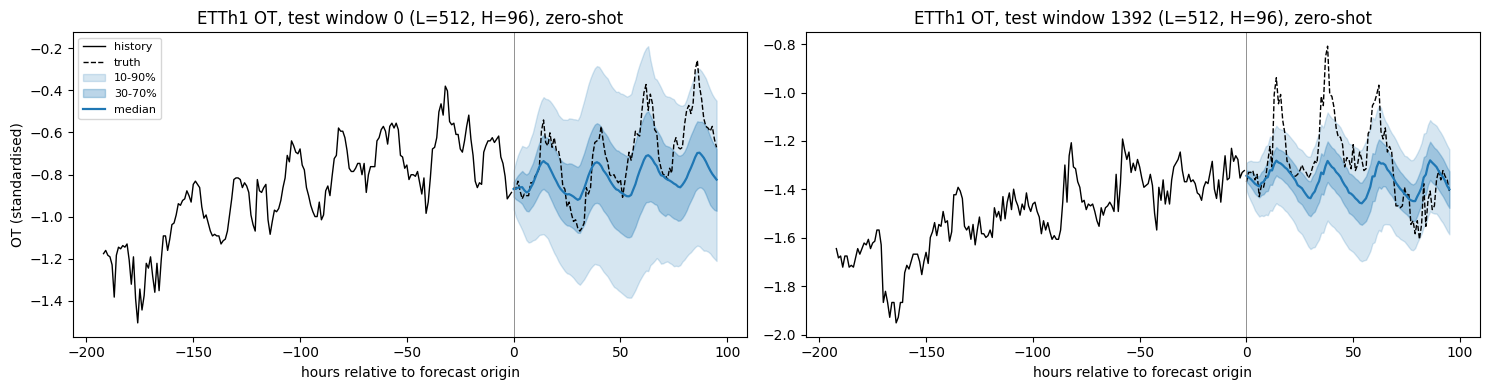

In [7]:
r = res[512]; c = cols.index("OT"); show_hist = 192
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=False)
for ax, k in zip(axes, [0, r["n_windows"] // 2]):
    hist, y, q = r["X"][k, -show_hist:, c], r["Y"][k, :, c], r["Q"][k, :, :, c]
    th, tf = np.arange(-show_hist, 0), np.arange(H)
    ax.plot(th, hist, color="k", lw=1, label="history")
    ax.plot(tf, y, color="k", lw=1, ls="--", label="truth")
    ax.fill_between(tf, q[0], q[-1], color="tab:blue", alpha=0.18, label="10-90%")
    ax.fill_between(tf, q[2], q[-3], color="tab:blue", alpha=0.30, label="30-70%")
    ax.plot(tf, q[MED], color="tab:blue", lw=1.6, label="median")
    ax.axvline(0, color="gray", lw=0.6)
    ax.set_title(f"ETTh1 OT, test window {k} (L=512, H=96), zero-shot")
    ax.set_xlabel("hours relative to forecast origin")
axes[0].set_ylabel("OT (standardised)"); axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## Results

ETTh1, H = 96, standardised data, stride-1 test windows, all 7 channels, median forecast. **The model was not trained on ETTh1 at all.**

There is no paper reference for this exact setting. The Moirai 2.0 paper reports only GIFT-Eval (MASE/CRPS) and no ETT long-term-forecasting numbers. As a loose anchor we print the supervised TSLib baselines (L = 96) and Moirai **1.0**-small's ETTh1 number from the Moirai 1.0 paper (ICML 2024, Table 6). That number is averaged over horizons {96, 192, 336, 720} with a tuned context length, so it is *not* directly comparable.

In [8]:
refs = {
    "DLinear (TSLib, L=96, supervised)": (0.386, 0.400),
    "PatchTST (TSLib, L=96, supervised)": (0.414, 0.419),
    "iTransformer (TSLib, L=96, supervised)": (0.386, 0.405),
    "TimesNet (TSLib, L=96, supervised)": (0.384, 0.402),
    "Moirai 1.0-small (ICML'24, avg H=96..720, zero-shot)": (0.400, 0.424),
}
print(f"{'model':58s} {'MSE':>7s} {'MAE':>7s}")
for L in (512, 96):
    print(f"{'Moirai 2.0-R-small zero-shot, L=%d (this notebook)' % L:58s} {res[L]['mse']:7.4f} {res[L]['mae']:7.4f}")
for k, (m, a) in refs.items():
    print(f"{k:58s} {m:7.3f} {a:7.3f}")

try:
    for L in (512, 96):
        out = {"model": "Moirai 2.0-R-small (zero-shot)",
               "paper": "Moirai 2.0: When Less Is More for Time Series Forecasting (arXiv:2511.11698)",
               "venue": "arXiv 2025", "type": "zero-shot foundation", "lookback": L, "horizon": H,
               "mse": res[L]["mse"], "mae": res[L]["mae"], "paper_mse": None, "paper_mae": None,
               "params": n_params, "train_or_infer_seconds": round(res[L]["seconds"], 2),
               "notes": (f"Salesforce/moirai-2.0-R-small via uni2ts {version('uni2ts')} (installed --no-deps on "
                         f"torch {torch.__version__}); channel-independent univariate; median (q=0.5) forecast; "
                         f"stride 1 ({res[L]['n_windows']} windows x 7 ch); 10-90% coverage "
                         f"{res[L]['coverage_10_90']:.3f}. Paper reports only GIFT-Eval, no ETTh1 number.")}
        fn = f"results_moirai2_zero_shot{'' if L == 512 else '_L96'}.json"
        with open(fn, "w") as fh: json.dump(out, fh, indent=2)
        print("wrote", fn)
except Exception as e:
    print("could not write results JSON:", e)

model                                                          MSE     MAE
Moirai 2.0-R-small zero-shot, L=512 (this notebook)         0.3838  0.3803
Moirai 2.0-R-small zero-shot, L=96 (this notebook)          0.4346  0.4028
DLinear (TSLib, L=96, supervised)                            0.386   0.400
PatchTST (TSLib, L=96, supervised)                           0.414   0.419
iTransformer (TSLib, L=96, supervised)                       0.386   0.405
TimesNet (TSLib, L=96, supervised)                           0.384   0.402
Moirai 1.0-small (ICML'24, avg H=96..720, zero-shot)         0.400   0.424
wrote results_moirai2_zero_shot.json
wrote results_moirai2_zero_shot_L96.json


## Using your own data

Moirai 2.0 needs no training. Pass any context as a `(batch, L, 1)` tensor and you get 9 quantiles per future step:

```python
f = make_forecaster(L=512, H=48)                         # any context / horizon length
x = torch.tensor(my_series[-512:], dtype=torch.float32).view(1, -1, 1).to(device)
q = f(past_target=x,
      past_observed_target=torch.isfinite(x),            # False marks missing values
      past_is_pad=torch.zeros(1, 512, dtype=torch.bool, device=device))
median, lo, hi = q[0, 4], q[0, 0], q[0, -1]              # (H,) each
```

- You do not need to standardise first, because the model scales each series internally. Missing values: set them to any finite number and mark them `False` in `past_observed_target` (or use `f.predict([np_array, ...])`, which applies causal-mean imputation and pads short series for you).
- For several related series, call it per series as above (channel-independent), or set `target_dim=k` to let the model attend across the `k` variates jointly.
- Larger checkpoints: swap in another Moirai 2.0 checkpoint if one is published on the Hugging Face hub. Longer contexts usually help on hourly data with daily/weekly seasonality.